In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

customers = pd.read_csv("E:\CODING_ALL\Data Analytics\projrcts\RetailIQ\data\Cleaned csv\cleaned_customers.csv")
products = pd.read_csv("E:\CODING_ALL\Data Analytics\projrcts\RetailIQ\data\Cleaned csv\cleaned_products.csv")
sales = pd.read_csv("E:\CODING_ALL\Data Analytics\projrcts\RetailIQ\data\Cleaned csv\cleaned_sales.csv")
order_items = pd.read_csv("E:\CODING_ALL\Data Analytics\projrcts\RetailIQ\data\Cleaned csv\cleaned_orders.csv")

print("Customers:", customers.shape)
print("Products:", products.shape)
print("Sales:", sales.shape)
print("Order Items:", order_items.shape)

Customers: (25000, 12)
Products: (1175, 10)
Sales: (138116, 26)
Order Items: (397569, 14)


In [3]:
customers.head()
products.head()
sales.head()
order_items.head()

,order_id,product_id,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit,expected_gross_sales,gross_sales_difference
0,ORD-301242,PROD-000738,2,244.40,0.339607,166.00,488.80,22.60,6.48,351.88,173.28,172.12,488.80,0.0
1,ORD-301242,PROD-000181,3,287.13,0.362076,311.89,861.39,38.47,5.55,593.52,415.05,172.92,861.39,0.0
2,ORD-773460,PROD-000973,4,754.80,0.468300,1413.89,3019.20,305.01,9.00,1919.32,1976.16,-65.84,3019.20,0.0
3,ORD-773460,PROD-000268,4,31.36,0.336182,42.17,125.44,15.82,0.00,99.09,55.72,43.37,125.44,0.0
4,ORD-449374,PROD-001040,3,6.31,0.089678,1.70,18.93,1.21,0.98,19.42,5.91,12.53,18.93,0.0


In [10]:
customers.columns.tolist()
products.columns.tolist()
sales.columns.tolist()
order_items.columns.tolist()

['order_id',
 'product_id',
 'quantity',
 'unit_price',
 'discount_percentage',
 'discount_amount',
 'gross_sales',
 'tax_amount',
 'shipping_cost',
 'net_sales',
 'product_cost',
 'profit',
 'expected_gross_sales',
 'gross_sales_difference']

In [11]:
customers.info()
products.info()
sales.info()
order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                25000 non-null  object 
 1   customer_name              25000 non-null  object 
 2   customer_age               25000 non-null  int64  
 3   age_range                  25000 non-null  object 
 4   gender                     25000 non-null  object 
 5   customer_segment           25000 non-null  object 
 6   customer_city              25000 non-null  object 
 7   customer_state             25000 non-null  object 
 8   customer_country           25000 non-null  object 
 9   region                     25000 non-null  object 
 10  customer_postal_code       25000 non-null  int64  
 11  customer_acquisition_cost  25000 non-null  float64
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIn

In [12]:
display(customers.describe().T)

,count,mean,std,min,25%,50%,75%,max
customer_age,25000.0,45.90784,16.454286,18.00,32.0000,46.00,60.00,74.00
customer_postal_code,25000.0,50183.06640,28596.584321,516.00,25374.5000,50303.00,74845.50,99950.00
customer_acquisition_cost,25000.0,42.15975,21.692648,5.01,23.2975,41.98,61.13,79.99


In [13]:
display(products.describe().T)

,count,mean,std,min,25%,50%,75%,max
unit_price,1175.0,245.524400,251.267683,6.31,74.710,165.42,311.295,1482.95
product_cost,1175.0,126.536826,150.131833,1.97,29.565,74.54,153.045,993.63
product_rating,1175.0,3.683064,0.698046,2.50,3.100,3.70,4.300,4.90
price_cost_difference,1175.0,118.987574,108.289840,3.28,41.865,87.74,157.855,624.22


In [14]:
display(sales.describe().T)

,count,mean,std,min,25%,50%,75%,max
delivery_days,113559.0,4.557772,2.810012,0.00,2.00,4.000,7.00,14.00
estimated_delivery_days,113559.0,4.298875,2.594080,0.00,2.00,4.000,6.00,10.00
rating,138116.0,3.068486,1.514408,0.00,3.00,4.000,4.00,5.00
customer_rating,113559.0,3.677015,0.483672,1.60,3.40,3.700,4.00,5.00
loyalty_points_earned,138116.0,103.991051,115.175640,0.00,17.00,70.000,151.00,1621.00
loyalty_points_redeemed,138116.0,51.934128,73.217692,0.00,3.00,25.000,71.00,1063.00
customer_lifetime_value,138116.0,8971.639047,4430.506588,22.55,5713.57,8392.525,11651.03,30268.44
customer_order_count,138116.0,6.990559,2.444166,1.00,5.00,7.000,9.00,20.00


In [15]:
display(order_items.describe().T)

,count,mean,std,min,25%,50%,75%,max
quantity,397569.0,2.118792e+00,1.196276e+00,1.000000e+00,1.000000,2.000000,3.000000,5.000000e+00
unit_price,397569.0,2.451891e+02,2.510351e+02,6.310000e+00,74.360000,164.970000,310.790000,1.482950e+03
discount_percentage,397569.0,1.470586e-01,1.299860e-01,0.000000e+00,0.048137,0.124253,0.199499,6.000000e-01
discount_amount,397569.0,8.966787e+01,1.906378e+02,0.000000e+00,5.940000,26.340000,86.030000,3.857670e+03
gross_sales,397569.0,5.190136e+02,6.768005e+02,6.310000e+00,122.000000,280.190000,643.560000,7.414750e+03
tax_amount,397569.0,4.618364e+01,7.107202e+01,2.600000e-01,9.560000,22.550000,52.340000,1.482950e+03
shipping_cost,397569.0,8.409010e+00,6.777155e+00,0.000000e+00,3.370000,5.870000,12.460000,3.646000e+01
net_sales,397569.0,4.839383e+02,6.154302e+02,5.350000e+00,124.280000,271.100000,595.240000,8.897700e+03
product_cost,397569.0,2.675200e+02,3.947736e+02,1.970000e+00,52.960000,127.100000,314.310000,4.968150e+03
profit,397569.0,2.080093e+02,2.664777e+02,-1.260280e+03,53.730000,121.660000,259.660000,4.045100e+03


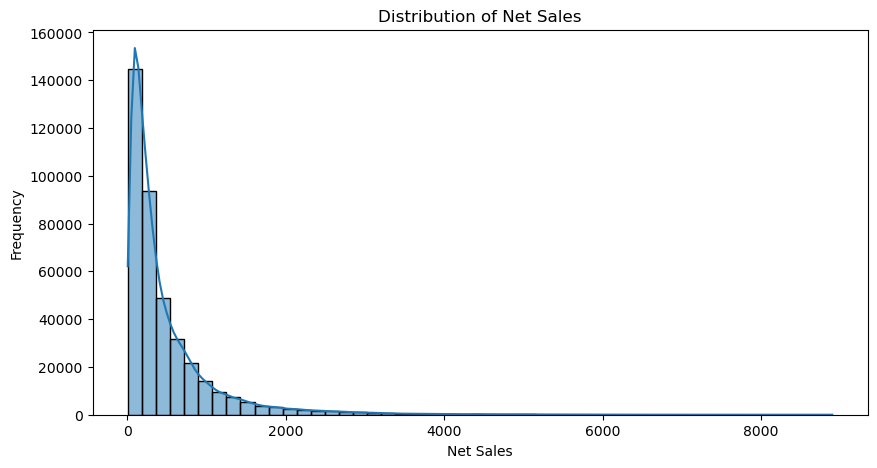

In [16]:
plt.figure(figsize=(10, 5))
sns.histplot(data=order_items, x="net_sales", bins=50, kde=True)
plt.title("Distribution of Net Sales")
plt.xlabel("Net Sales")
plt.ylabel("Frequency")
plt.show()

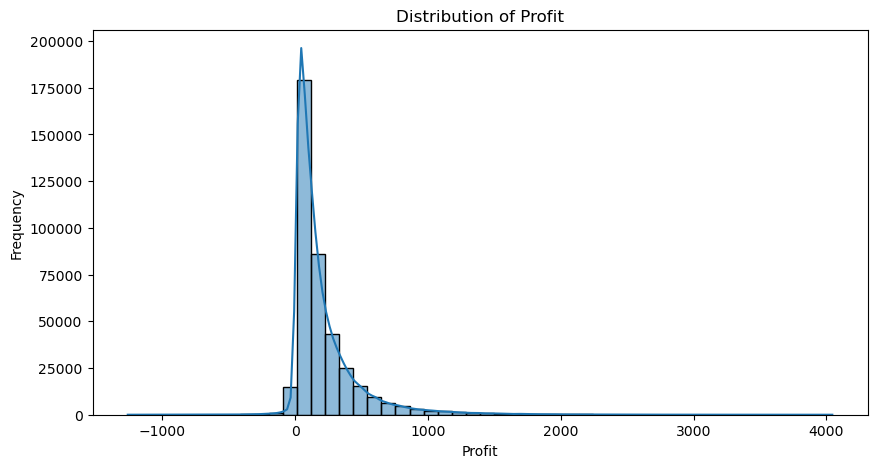

In [17]:
plt.figure(figsize=(10, 5))
sns.histplot(data=order_items, x="profit", bins=50, kde=True)
plt.title("Distribution of Profit")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.show()

In [18]:
sales["order_date"] = pd.to_datetime(
    sales["order_date"], errors="coerce"
)

sales["year"] = sales["order_date"].dt.year
sales["month"] = sales["order_date"].dt.to_period("M")

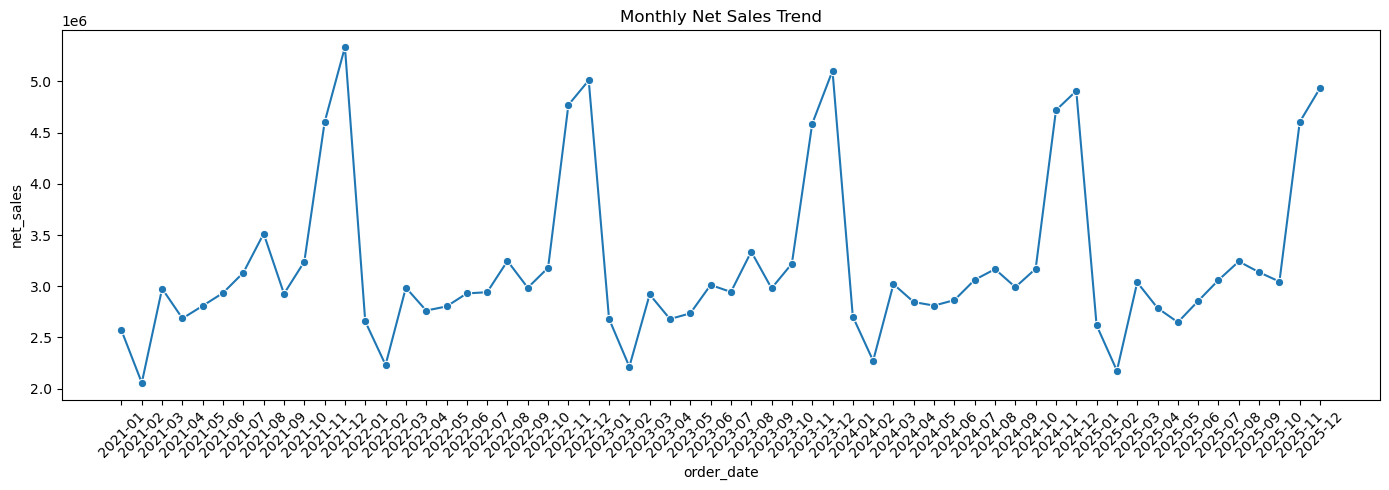

In [19]:
monthly_data = order_items.merge(
    sales[["order_id", "order_date"]],
    on="order_id",
    how="left"
)

monthly_sales = (
    monthly_data.groupby(
        monthly_data["order_date"].dt.to_period("M")
    )
    .agg(
        net_sales=("net_sales", "sum"),
        profit=("profit", "sum")
    )
    .reset_index()
)

monthly_sales["order_date"] = (
    monthly_sales["order_date"].astype(str)
)

plt.figure(figsize=(14, 5))
sns.lineplot(
    data=monthly_sales,
    x="order_date",
    y="net_sales",
    marker="o"
)
plt.xticks(rotation=45)
plt.title("Monthly Net Sales Trend")
plt.tight_layout()
plt.show()

## Category, product, country and regional performance

In [31]:
## A. Category performance
product_sales = order_items.merge(
    products[["product_id", "product_category", "product_name"]],
    on="product_id",
    how="left"
)

category_performance = (
    product_sales.groupby("product_category")
    .agg(
        net_sales=("net_sales", "sum"),
        profit=("profit", "sum"),
        units_sold=("quantity", "sum")
    )
    .sort_values("net_sales", ascending=False)
)

display(category_performance)

,net_sales,profit,units_sold
product_category,,,
Electronics,41148162.90,14103982.74,55784
Jewelry,25561333.78,10391635.32,48859
Home Appliances,24842478.64,10288878.45,56281
Automotive,16449898.28,6477194.28,58046
Sports & Outdoors,15726848.17,7230037.31,64752
Home & Kitchen,10971629.82,5203824.25,49682
Baby & Kids,9690605.60,4818148.07,53945
Health & Wellness,9228068.04,4263304.41,62054
Office Supplies,8884212.85,4585377.04,57631


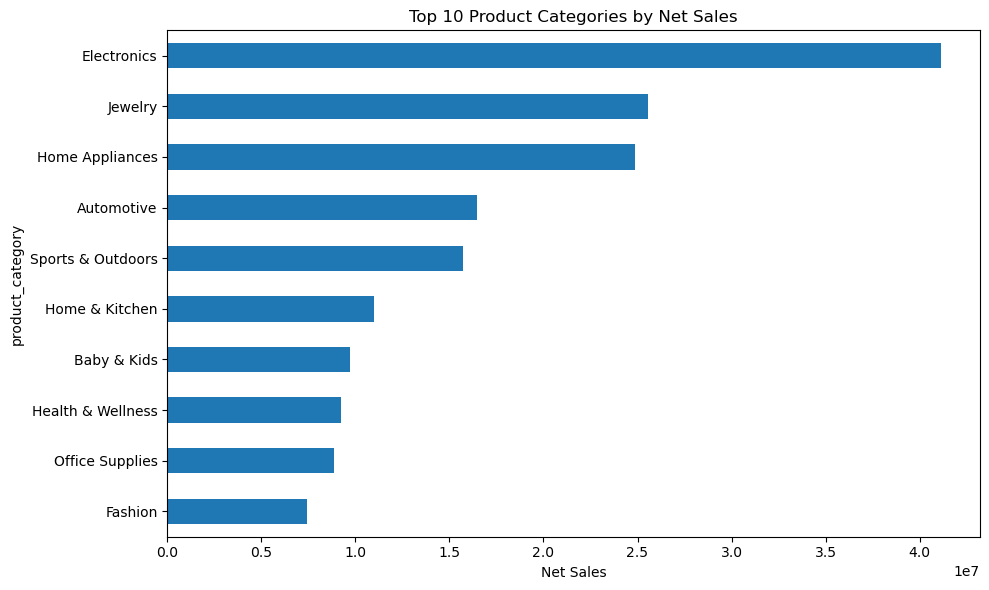

In [21]:
category_performance.head(10)["net_sales"].sort_values().plot(
    kind="barh", figsize=(10, 6)
)
plt.title("Top 10 Product Categories by Net Sales")
plt.xlabel("Net Sales")
plt.tight_layout()
plt.show()

In [30]:
## B. Country and regional performance
regional_data = sales.merge(
    customers[["customer_id", "customer_country", "region"]],
    on="customer_id",
    how="left"
)

regional_performance = (
    regional_data.groupby(["customer_country", "region"])
    .agg(
        orders=("order_id", "nunique"),
        customers=("customer_id", "nunique")
    )
    .sort_values("orders", ascending=False)
)

display(regional_performance.head(20))

orders  customers
customer_country region                    
USA              South     32047       5807
                 Central   24451       4409
                 East      17579       3139
UK               North     10146       1834
                 West      10089       1855
USA              West       8523       1524
Germany          South      4545        802
Australia        South      2883        533
Canada           Central    2866        521
                 East       2566        471
Germany          West       2507        426
India            South      2339        420
Germany          Central    2310        415
                 North      2231        396
UAE              South      2176        402
India            West       2159        393
UAE              North      1996        369
Canada           West       1583        280
Australia        East       1457        250
                 West       1412        253

## Customer spending, purchase frequency and discounts

In [23]:
## A. Customer purchase frequency
customer_frequency = (
    sales.groupby("customer_id")
    .agg(total_orders=("order_id", "nunique"))
)

customer_frequency["total_orders"].describe()

count    24911.000000
mean         5.544378
std          2.318296
min          1.000000
25%          4.000000
50%          5.000000
75%          7.000000
max         19.000000
Name: total_orders, dtype: float64

In [24]:
##B. Customer spending
order_totals = (
    order_items.groupby("order_id")
    .agg(order_net_sales=("net_sales", "sum"))
    .reset_index()
)

customer_spending = sales[
    ["order_id", "customer_id"]
].merge(
    order_totals,
    on="order_id",
    how="left"
)

customer_spending = (
    customer_spending.groupby("customer_id")
    .agg(
        total_spending=("order_net_sales", "sum"),
        total_orders=("order_id", "nunique")
    )
    .sort_values("total_spending", ascending=False)
)

display(customer_spending.head(20))

,total_spending,total_orders
customer_id,,
CUST-012869,36882.29,15
CUST-011800,35447.76,12
CUST-009330,32884.83,13
CUST-018228,32564.96,14
CUST-017251,31378.08,15
CUST-017828,31330.87,14
CUST-022868,30823.46,11
CUST-009693,30719.47,9
CUST-002969,30061.58,16


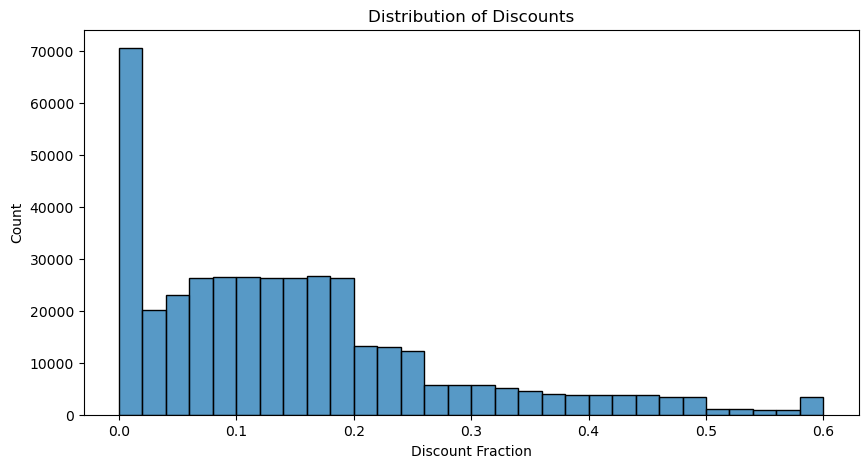

In [25]:
## C. Discount distribution
plt.figure(figsize=(10, 5))
sns.histplot(
    data=order_items,
    x="discount_percentage",
    bins=30
)
plt.title("Distribution of Discounts")
plt.xlabel("Discount Fraction")
plt.show()

## Returns, cancellations, delivery delays and ratings

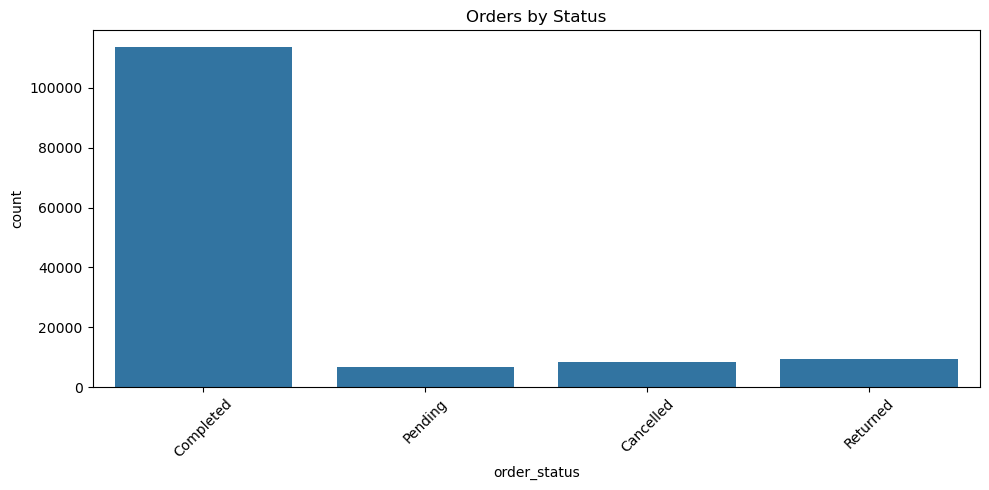

In [26]:
## A. Returns and cancellations
plt.figure(figsize=(10, 5))
sns.countplot(data=sales, x="order_status")
plt.title("Orders by Status")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
display(
    sales["return_status"]
    .value_counts(dropna=False)
)

return_status
NaN         128654
Returned      9462
Name: count, dtype: int64

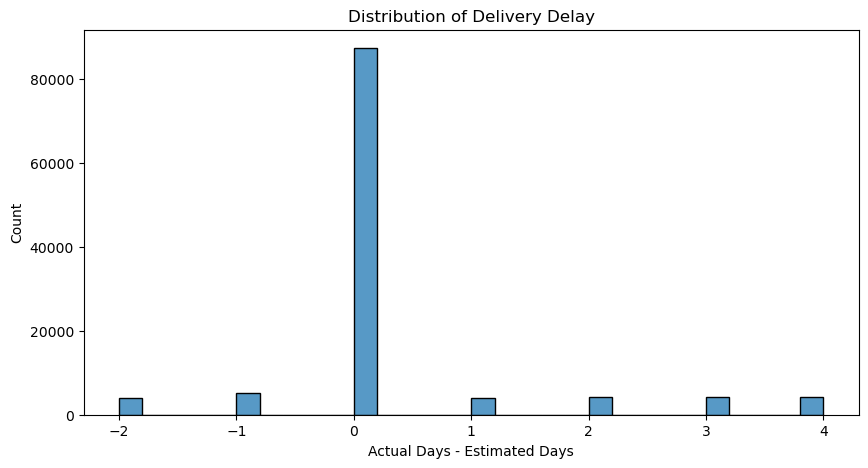

In [28]:
## B. Delivery delays
sales["delivery_delay"] = (
    sales["delivery_days"]
    - sales["estimated_delivery_days"]
)

plt.figure(figsize=(10, 5))
sns.histplot(
    data=sales,
    x="delivery_delay",
    bins=30
)
plt.title("Distribution of Delivery Delay")
plt.xlabel("Actual Days - Estimated Days")
plt.show()

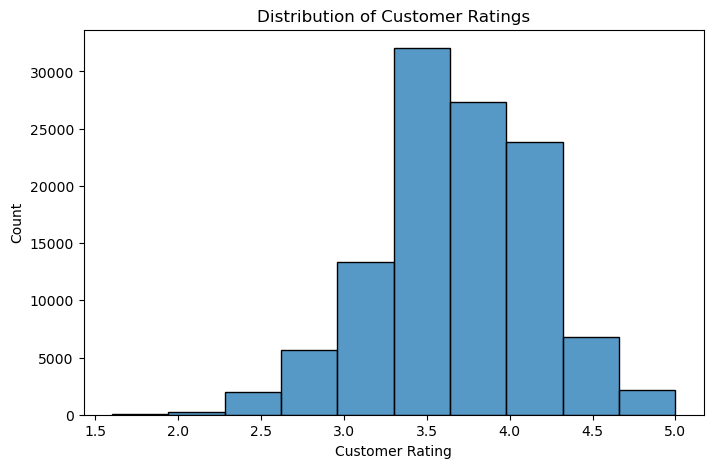

In [29]:
## C. Customer ratings
plt.figure(figsize=(8, 5))
sns.histplot(
    data=sales,
    x="customer_rating",
    bins=10
)
plt.title("Distribution of Customer Ratings")
plt.xlabel("Customer Rating")
plt.show()